# Практическая работа № 3 — расчёты по собственной статистике SSH brute-force

В ноутбуке все четыре задания из практической работы адаптированы к вашему временному ряду: **101 наблюдение количества SSH-инцидентов с шагом 30 секунд** за период **03.09.2026 10:26:30–11:16:30**.

Используются:
- метод Фостера–Стюарта;
- прогноз по среднему абсолютному приросту;
- прогноз по среднему темпу роста;
- цепные, базисные и средние показатели динамики.

Дополнительный файл в Colab загружать не требуется: исходный ряд встроен в ноутбук.

Количество обучающих наблюдений: 59
Количество проверочных наблюдений: 30

ЛИНЕЙНАЯ МОДЕЛЬ ТРЕНДА
y = 21.490357 + 0.009643 * t

ОЦЕНКА КАЧЕСТВА ПРОГНОЗА
MAE  = 2.4111
MSE   = 9.4984
RMSE  = 3.0819
MAPE  = 11.64%

СРАВНЕНИЕ ПРОГНОЗА С РЕАЛЬНЫМИ ДАННЫМИ:


,Номер наблюдения,Фактическое значение,Прогноз по тренду,Абсолютная ошибка,"Относительная ошибка, %"
0,60,25,22.069,2.931,11.72
1,61,21,22.079,1.079,5.14
2,62,23,22.088,0.912,3.96
3,63,29,22.098,6.902,23.80
4,64,24,22.108,1.892,7.89
5,65,24,22.117,1.883,7.85
6,66,23,22.127,0.873,3.80
7,67,24,22.136,1.864,7.76
8,68,26,22.146,3.854,14.82
9,69,23,22.156,0.844,3.67


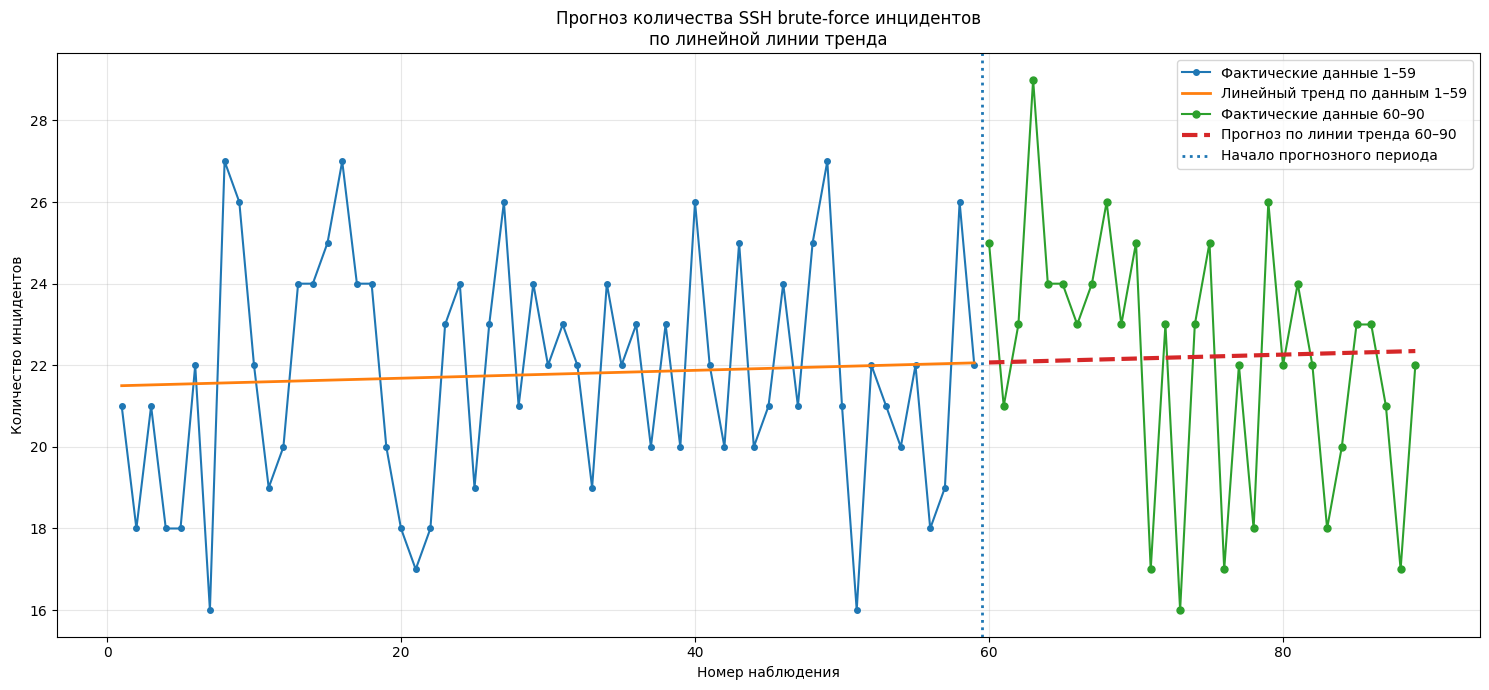

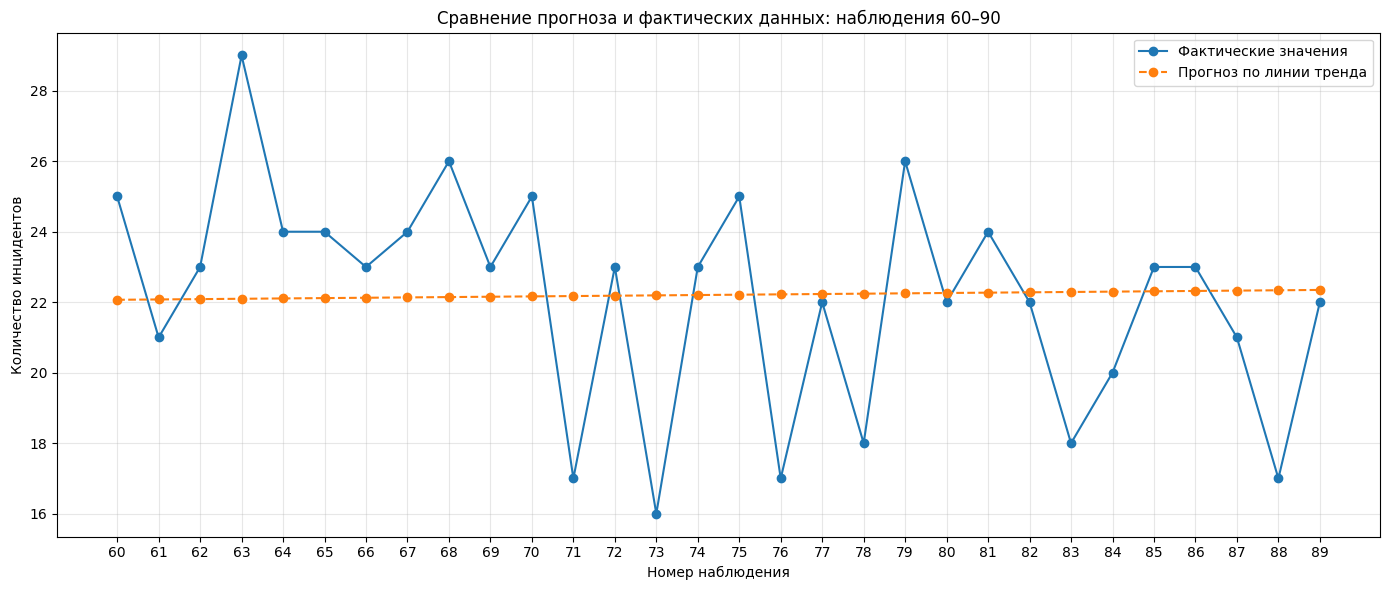

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ============================================================
# ИСХОДНЫЕ ДАННЫЕ
# Количество SSH brute-force инцидентов каждые 30 секунд
# ============================================================

y = np.array([
    21, 18, 21, 18, 18, 22, 16, 27, 26, 22,
    19, 20, 24, 24, 25, 27, 24, 24, 20, 18,
    17, 18, 23, 24, 19, 23, 26, 21, 24, 22,
    23, 22, 19, 24, 22, 23, 20, 23, 20, 26,
    22, 20, 25, 20, 21, 24, 21, 25, 27, 21,
    16, 22, 21, 20, 22, 18, 19, 26, 22,
    # С 60-го значения начинается проверочная выборка
    25, 21, 23, 29, 24, 24, 23, 24, 26, 23,
    25, 17, 23, 16, 23, 25, 17, 22, 18, 26,
    22, 24, 22, 18, 20, 23, 23, 21, 17, 22
])

# Номера наблюдений: 1, 2, ..., 90
t = np.arange(1, len(y) + 1)

# ============================================================
# 1. РАЗДЕЛЕНИЕ ДАННЫХ
# ============================================================

# Обучение: наблюдения 1–59
t_train = t[:59]
y_train = y[:59]

# Проверка: наблюдения 60–90
t_test = t[59:90]
y_test = y[59:90]

print("Количество обучающих наблюдений:", len(y_train))
print("Количество проверочных наблюдений:", len(y_test))

# ============================================================
# 2. ПОСТРОЕНИЕ ЛИНЕЙНОЙ ЛИНИИ ТРЕНДА
#
# Формула:
# y = a * t + b
# ============================================================

a, b = np.polyfit(t_train, y_train, 1)

print("\nЛИНЕЙНАЯ МОДЕЛЬ ТРЕНДА")
print(f"y = {b:.6f} + {a:.6f} * t")

# ============================================================
# 3. РАСЧЕТ ЛИНИИ ТРЕНДА НА УЧАСТКЕ 1–59
# ============================================================

y_train_trend = b + a * t_train

# ============================================================
# 4. ПРОГНОЗ ДЛЯ НАБЛЮДЕНИЙ 60–90
# ============================================================

y_pred = b + a * t_test

# ============================================================
# 5. РАСЧЕТ ОШИБОК
# ============================================================

absolute_error = np.abs(y_test - y_pred)

relative_error = absolute_error / y_test * 100

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mape = np.mean(relative_error)

print("\nОЦЕНКА КАЧЕСТВА ПРОГНОЗА")
print(f"MAE  = {mae:.4f}")
print(f"MSE   = {mse:.4f}")
print(f"RMSE  = {rmse:.4f}")
print(f"MAPE  = {mape:.2f}%")

# ============================================================
# 6. ТАБЛИЦА ФАКТИЧЕСКИХ И ПРОГНОЗНЫХ ЗНАЧЕНИЙ
# ============================================================

result = pd.DataFrame({
    "Номер наблюдения": t_test,
    "Фактическое значение": y_test,
    "Прогноз по тренду": np.round(y_pred, 3),
    "Абсолютная ошибка": np.round(absolute_error, 3),
    "Относительная ошибка, %": np.round(relative_error, 2)
})

print("\nСРАВНЕНИЕ ПРОГНОЗА С РЕАЛЬНЫМИ ДАННЫМИ:")
display(result)

# ============================================================
# 7. ГРАФИК
# ============================================================

plt.figure(figsize=(15, 7))

# Реальные значения 1–59
plt.plot(
    t_train,
    y_train,
    marker='o',
    markersize=4,
    label='Фактические данные 1–59'
)

# Линия тренда, полученная по 1–59
plt.plot(
    t_train,
    y_train_trend,
    linewidth=2,
    label='Линейный тренд по данным 1–59'
)

# Реальные значения 60–90
plt.plot(
    t_test,
    y_test,
    marker='o',
    markersize=5,
    label='Фактические данные 60–90'
)

# Прогноз на 60–90
plt.plot(
    t_test,
    y_pred,
    linestyle='--',
    linewidth=3,
    label='Прогноз по линии тренда 60–90'
)

# Граница между обучением и прогнозом
plt.axvline(
    x=59.5,
    linestyle=':',
    linewidth=2,
    label='Начало прогнозного периода'
)

plt.title(
    'Прогноз количества SSH brute-force инцидентов\n'
    'по линейной линии тренда'
)

plt.xlabel('Номер наблюдения')
plt.ylabel('Количество инцидентов')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

# ============================================================
# 8. ОТДЕЛЬНЫЙ ГРАФИК ТОЛЬКО ДЛЯ СРАВНЕНИЯ 60–90
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    t_test,
    y_test,
    marker='o',
    label='Фактические значения'
)

plt.plot(
    t_test,
    y_pred,
    marker='o',
    linestyle='--',
    label='Прогноз по линии тренда'
)

plt.title('Сравнение прогноза и фактических данных: наблюдения 60–90')
plt.xlabel('Номер наблюдения')
plt.ylabel('Количество инцидентов')

plt.xticks(t_test)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

pd.set_option("display.float_format", lambda x: f"{x:.4f}")

dates = pd.to_datetime(['2026-09-03 10:26:30', '2026-09-03 10:27:00', '2026-09-03 10:27:30', '2026-09-03 10:28:00', '2026-09-03 10:28:30', '2026-09-03 10:29:00', '2026-09-03 10:29:30', '2026-09-03 10:30:00', '2026-09-03 10:30:30', '2026-09-03 10:31:00', '2026-09-03 10:31:30', '2026-09-03 10:32:00', '2026-09-03 10:32:30', '2026-09-03 10:33:00', '2026-09-03 10:33:30', '2026-09-03 10:34:00', '2026-09-03 10:34:30', '2026-09-03 10:35:00', '2026-09-03 10:35:30', '2026-09-03 10:36:00', '2026-09-03 10:36:30', '2026-09-03 10:37:00', '2026-09-03 10:37:30', '2026-09-03 10:38:00', '2026-09-03 10:38:30', '2026-09-03 10:39:00', '2026-09-03 10:39:30', '2026-09-03 10:40:00', '2026-09-03 10:40:30', '2026-09-03 10:41:00', '2026-09-03 10:41:30', '2026-09-03 10:42:00', '2026-09-03 10:42:30', '2026-09-03 10:43:00', '2026-09-03 10:43:30', '2026-09-03 10:44:00', '2026-09-03 10:44:30', '2026-09-03 10:45:00', '2026-09-03 10:45:30', '2026-09-03 10:46:00', '2026-09-03 10:46:30', '2026-09-03 10:47:00', '2026-09-03 10:47:30', '2026-09-03 10:48:00', '2026-09-03 10:48:30', '2026-09-03 10:49:00', '2026-09-03 10:49:30', '2026-09-03 10:50:00', '2026-09-03 10:50:30', '2026-09-03 10:51:00', '2026-09-03 10:51:30', '2026-09-03 10:52:00', '2026-09-03 10:52:30', '2026-09-03 10:53:00', '2026-09-03 10:53:30', '2026-09-03 10:54:00', '2026-09-03 10:54:30', '2026-09-03 10:55:00', '2026-09-03 10:55:30', '2026-09-03 10:56:00', '2026-09-03 10:56:30', '2026-09-03 10:57:00', '2026-09-03 10:57:30', '2026-09-03 10:58:00', '2026-09-03 10:58:30', '2026-09-03 10:59:00', '2026-09-03 10:59:30', '2026-09-03 11:00:00', '2026-09-03 11:00:30', '2026-09-03 11:01:00', '2026-09-03 11:01:30', '2026-09-03 11:02:00', '2026-09-03 11:02:30', '2026-09-03 11:03:00', '2026-09-03 11:03:30', '2026-09-03 11:04:00', '2026-09-03 11:04:30', '2026-09-03 11:05:00', '2026-09-03 11:05:30', '2026-09-03 11:06:00', '2026-09-03 11:06:30', '2026-09-03 11:07:00', '2026-09-03 11:07:30', '2026-09-03 11:08:00', '2026-09-03 11:08:30', '2026-09-03 11:09:00', '2026-09-03 11:09:30', '2026-09-03 11:10:00', '2026-09-03 11:10:30', '2026-09-03 11:11:00', '2026-09-03 11:11:30', '2026-09-03 11:12:00', '2026-09-03 11:12:30', '2026-09-03 11:13:00', '2026-09-03 11:13:30', '2026-09-03 11:14:00', '2026-09-03 11:14:30', '2026-09-03 11:15:00', '2026-09-03 11:15:30', '2026-09-03 11:16:00', '2026-09-03 11:16:30'])
y = np.array([21, 18, 21, 18, 18, 22, 16, 27, 26, 22, 19, 20, 24, 24, 25, 27, 24, 24, 20, 18, 17, 18, 23, 24, 19, 23, 26, 21, 24, 22, 23, 22, 19, 24, 22, 23, 20, 23, 20, 26, 22, 20, 25, 20, 21, 24, 21, 25, 27, 21, 16, 22, 21, 20, 22, 18, 19, 26, 22, 25, 21, 23, 29, 24, 24, 23, 24, 26, 23, 25, 17, 23, 16, 23, 25, 17, 22, 18, 26, 22, 24, 22, 18, 20, 23, 23, 21, 17, 22, 24, 21, 23, 19, 24, 18, 23, 20, 20, 23, 24, 22], dtype=float)

df = pd.DataFrame({"Дата": dates, "Количество инцидентов": y})
print(f"Количество наблюдений: {len(df)}")
print(f"Период: {df['Дата'].iloc[0]} — {df['Дата'].iloc[-1]}")
print(f"Среднее: {y.mean():.4f}, минимум: {y.min():.0f}, максимум: {y.max():.0f}")
display(df.head())

Количество наблюдений: 101
Период: 2026-09-03 10:26:30 — 2026-09-03 11:16:30
Среднее: 21.9010, минимум: 16, максимум: 29


,Дата,Количество инцидентов
0,2026-09-03 10:26:30,21.0000
1,2026-09-03 10:27:00,18.0000
2,2026-09-03 10:27:30,21.0000
3,2026-09-03 10:28:00,18.0000
4,2026-09-03 10:28:30,18.0000


## Задание 1. Проверка отсутствия тенденции методом Фостера–Стюарта

Для каждого уровня ряда, начиная со второго, вводятся индикаторы нового максимума и нового минимума:

$$u_i=1,\; \text{если } y_i>\max(y_1,\ldots,y_{i-1}),$$

$$l_i=1,\; \text{если } y_i<\min(y_1,\ldots,y_{i-1}).$$

Затем:

$$d=\sum(u_i-l_i), \qquad S=\sum(u_i+l_i).$$

Для проверки тенденции среднего уровня и дисперсии рассчитываются $t_d$ и $t_S$. Доверительная вероятность — 0,95.

In [3]:
n = len(y)
u, l = [], []
for i in range(1, n):
    prev = y[:i]
    u.append(1 if y[i] > prev.max() else 0)
    l.append(1 if y[i] < prev.min() else 0)

u = np.array(u); l = np.array(l)
d = np.sum(u-l)
S = np.sum(u+l)
mu_S = 2 * sum(1/i for i in range(2, n+1))
sigma_S = np.sqrt(2 * sum(1/i - 2/i**2 for i in range(2, n+1)))
sigma_d = np.sqrt(2 * sum(1/i for i in range(2, n+1)))
t_S = (S-mu_S)/sigma_S
t_d = d/sigma_d
t_crit = student_t.ppf(0.975, df=n-1)

fs = pd.DataFrame({
    't': np.arange(2,n+1), 'y_t': y[1:],
    'u_i': u, 'l_i': l
})
display(fs)
print(f'd = {d}; S = {S}')
print(f'μ_S = {mu_S:.4f}; σ_S = {sigma_S:.4f}; σ_d = {sigma_d:.4f}')
print(f't_d = {t_d:.4f}; t_S = {t_S:.4f}; t_кр = {t_crit:.4f}')
print('Тенденция среднего уровня:', 'ЕСТЬ' if abs(t_d)>t_crit else 'НЕ выявлена')
print('Тенденция дисперсии:', 'ЕСТЬ' if abs(t_S)>t_crit else 'НЕ выявлена')

,t,y_t,u_i,l_i
0,2,18.0000,0,1
1,3,21.0000,0,0
2,4,18.0000,0,0
3,5,18.0000,0,0
4,6,22.0000,1,0
...,...,...,...,...
95,97,20.0000,0,0
96,98,20.0000,0,0
97,99,23.0000,0,0
98,100,24.0000,0,0


d = 1; S = 5
μ_S = 8.3946; σ_S = 2.4196; σ_d = 2.8973
t_d = 0.3451; t_S = -1.4030; t_кр = 1.9840
Тенденция среднего уровня: НЕ выявлена
Тенденция дисперсии: НЕ выявлена


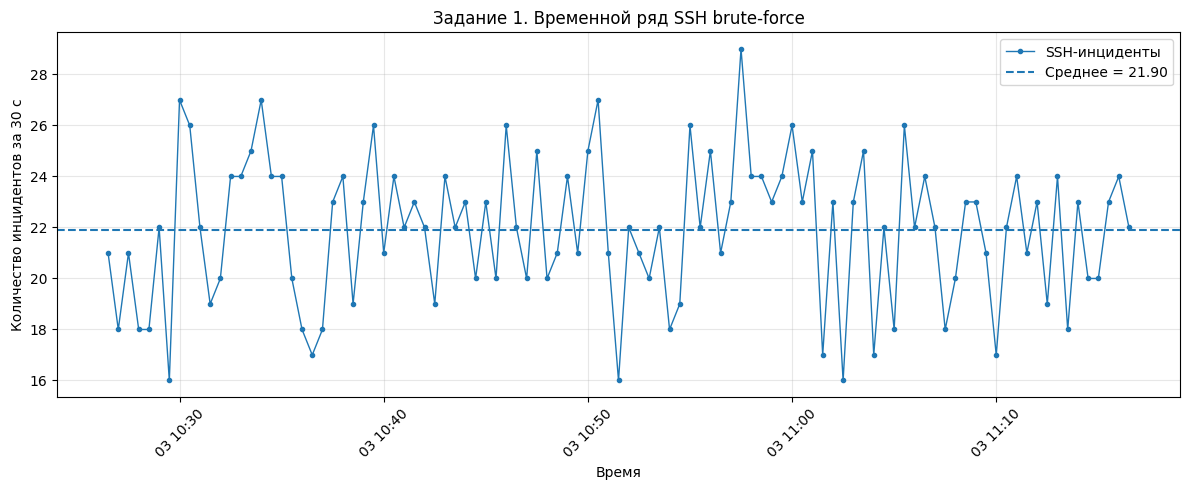

In [4]:
plt.figure(figsize=(12,5))
plt.plot(dates, y, marker='o', markersize=3, linewidth=1, label='SSH-инциденты')
plt.axhline(y.mean(), linestyle='--', label=f'Среднее = {y.mean():.2f}')
plt.xlabel('Время')
plt.ylabel('Количество инцидентов за 30 с')
plt.title('Задание 1. Временной ряд SSH brute-force')
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Задание 2. Прогноз по среднему абсолютному приросту

$$\overline{\Delta}=\frac{y_n-y_1}{n-1}, \qquad \hat y_{n+1}=y_n+\overline{\Delta}.$$

Для нашего ряда один шаг прогноза соответствует **30 секундам**.

In [5]:
chain_abs = np.diff(y)
avg_abs = (y[-1]-y[0])/(len(y)-1)
forecast_abs = y[-1] + avg_abs
std_abs = np.std(chain_abs, ddof=1)
next_time = dates[-1] + pd.Timedelta(seconds=30)

print(f'Средний абсолютный прирост = {avg_abs:.4f} инцидента за 30 с')
print(f'Стандартное отклонение цепных приростов = {std_abs:.4f}')
print(f'Диапазон цепных приростов: {chain_abs.min():.0f} ... {chain_abs.max():.0f}')
print(f'Прогноз на {next_time}: {forecast_abs:.4f} инцидента')
print('Комментарий: средний прирост близок к нулю, но отдельные изменения велики;')
print('поэтому метод пригоден прежде всего как простой базовый одношаговый прогноз.')

Средний абсолютный прирост = 0.0100 инцидента за 30 с
Стандартное отклонение цепных приростов = 3.9067
Диапазон цепных приростов: -8 ... 11
Прогноз на 2026-09-03 11:17:00: 22.0100 инцидента
Комментарий: средний прирост близок к нулю, но отдельные изменения велики;
поэтому метод пригоден прежде всего как простой базовый одношаговый прогноз.


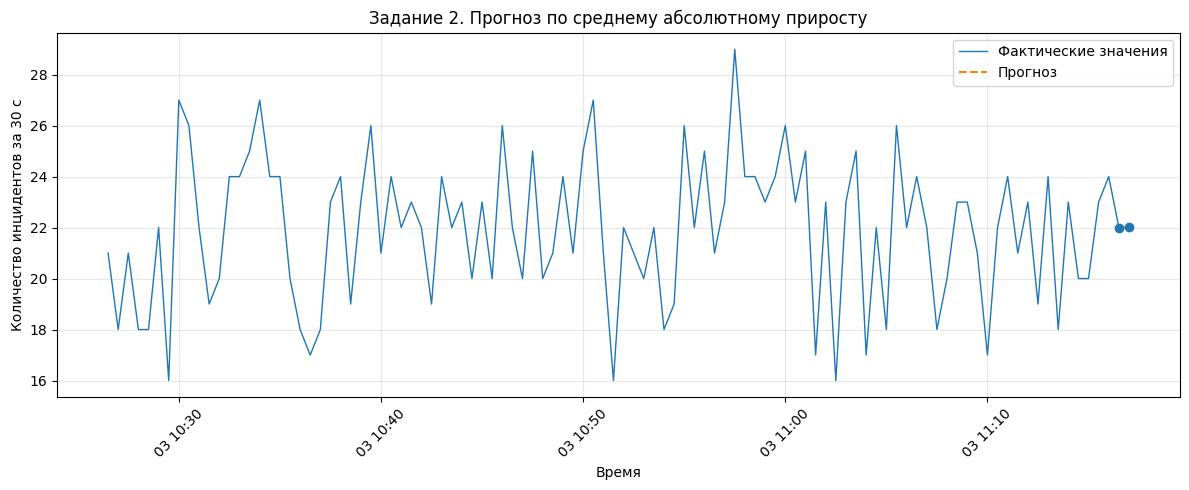

In [6]:
plt.figure(figsize=(12,5))
plt.plot(dates, y, linewidth=1, label='Фактические значения')
plt.scatter([dates[-1], next_time], [y[-1], forecast_abs], zorder=3)
plt.plot([dates[-1], next_time], [y[-1], forecast_abs], linestyle='--', label='Прогноз')
plt.xlabel('Время')
plt.ylabel('Количество инцидентов за 30 с')
plt.title('Задание 2. Прогноз по среднему абсолютному приросту')
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Задание 3. Прогноз по среднему темпу роста

$$\overline{K}_p=\sqrt[n-1]{\frac{y_n}{y_1}},$$

$$\overline{T}_p=\overline{K}_p\cdot100\%,$$

$$\hat y_{n+1}=y_n\cdot\overline{K}_p.$$


In [7]:
avg_growth_coef = (y[-1]/y[0]) ** (1/(len(y)-1))
avg_growth_rate = avg_growth_coef*100
avg_increment_rate = (avg_growth_coef-1)*100
forecast_growth = y[-1]*avg_growth_coef

print(f'Средний коэффициент роста = {avg_growth_coef:.8f}')
print(f'Средний темп роста = {avg_growth_rate:.6f}%')
print(f'Средний темп прироста = {avg_increment_rate:.6f}% за 30 с')
print(f'Прогноз на {next_time}: {forecast_growth:.4f} инцидента')

Средний коэффициент роста = 1.00046531
Средний темп роста = 100.046531%
Средний темп прироста = 0.046531% за 30 с
Прогноз на 2026-09-03 11:17:00: 22.0102 инцидента


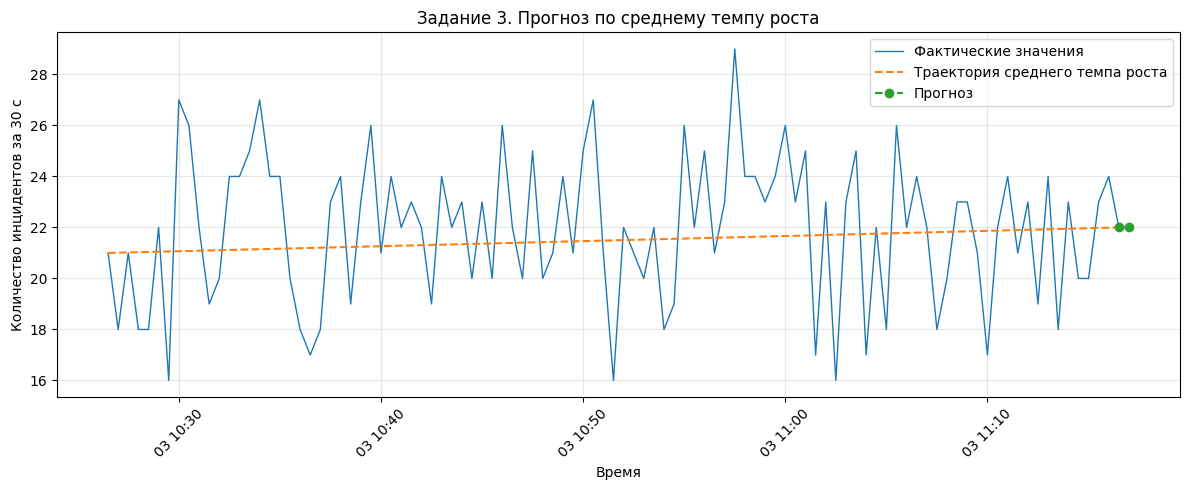

In [8]:
model_growth = y[0] * avg_growth_coef ** np.arange(len(y))
plt.figure(figsize=(12,5))
plt.plot(dates, y, linewidth=1, label='Фактические значения')
plt.plot(dates, model_growth, linestyle='--', label='Траектория среднего темпа роста')
plt.plot([dates[-1], next_time], [y[-1], forecast_growth], linestyle='--', marker='o', label='Прогноз')
plt.xlabel('Время')
plt.ylabel('Количество инцидентов за 30 с')
plt.title('Задание 3. Прогноз по среднему темпу роста')
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Задание 4. Цепные, базисные и средние показатели динамики

Вычисляются цепные и базисные абсолютные приросты, темпы роста и темпы прироста для всех 101 наблюдения. В качестве базисного уровня используется первое значение ряда.

In [9]:
chain_abs_full = np.r_[np.nan, np.diff(y)]
base_abs = y-y[0]
chain_growth = np.r_[np.nan, y[1:]/y[:-1]*100]
base_growth = y/y[0]*100
chain_increment = np.r_[np.nan, (y[1:]/y[:-1]-1)*100]
base_increment = (y/y[0]-1)*100

result = pd.DataFrame({
    'Дата': dates, 'y_t': y,
    'Δ цепной': chain_abs_full, 'Δ базисный': base_abs,
    'Темп роста цепной, %': chain_growth,
    'Темп роста базисный, %': base_growth,
    'Темп прироста цепной, %': chain_increment,
    'Темп прироста базисный, %': base_increment
})

display(result)
print(f'Средний абсолютный прирост = {avg_abs:.4f}')
print(f'Средний темп роста = {avg_growth_rate:.6f}%')
print(f'Средний темп прироста = {avg_increment_rate:.6f}%')
print(f'Прогноз следующего уровня по среднему абсолютному приросту = {forecast_abs:.4f}')

,Дата,y_t,Δ цепной,Δ базисный,"Темп роста цепной, %","Темп роста базисный, %","Темп прироста цепной, %","Темп прироста базисный, %"
0,2026-09-03 10:26:30,21.0000,NaN,0.0000,NaN,100.0000,NaN,0.0000
1,2026-09-03 10:27:00,18.0000,-3.0000,-3.0000,85.7143,85.7143,-14.2857,-14.2857
2,2026-09-03 10:27:30,21.0000,3.0000,0.0000,116.6667,100.0000,16.6667,0.0000
3,2026-09-03 10:28:00,18.0000,-3.0000,-3.0000,85.7143,85.7143,-14.2857,-14.2857
4,2026-09-03 10:28:30,18.0000,0.0000,-3.0000,100.0000,85.7143,0.0000,-14.2857
...,...,...,...,...,...,...,...,...
96,2026-09-03 11:14:30,20.0000,-3.0000,-1.0000,86.9565,95.2381,-13.0435,-4.7619
97,2026-09-03 11:15:00,20.0000,0.0000,-1.0000,100.0000,95.2381,0.0000,-4.7619
98,2026-09-03 11:15:30,23.0000,3.0000,2.0000,115.0000,109.5238,15.0000,9.5238
99,2026-09-03 11:16:00,24.0000,1.0000,3.0000,104.3478,114.2857,4.3478,14.2857


Средний абсолютный прирост = 0.0100
Средний темп роста = 100.046531%
Средний темп прироста = 0.046531%
Прогноз следующего уровня по среднему абсолютному приросту = 22.0100


,Показатель,Значение
0,Первый уровень,21.0000
1,Последний уровень,22.0000
2,Среднее,21.9010
3,Минимум,16.0000
4,Максимум,29.0000
5,Прогноз Δ,22.0100
6,Прогноз Tроста,22.0102


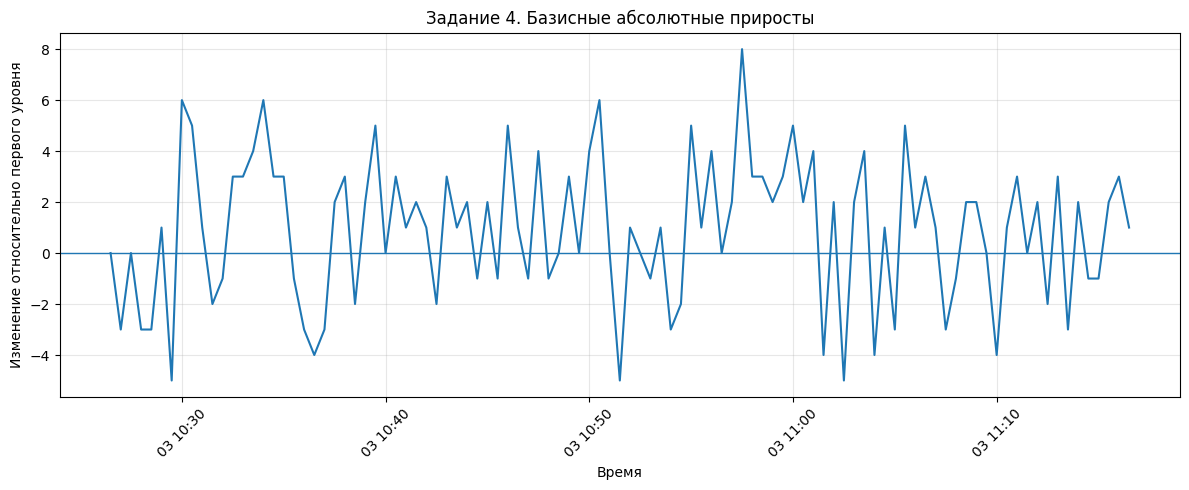

In [10]:
fig_data = pd.DataFrame({
    'Показатель': ['Первый уровень','Последний уровень','Среднее','Минимум','Максимум','Прогноз Δ','Прогноз Tроста'],
    'Значение': [y[0],y[-1],y.mean(),y.min(),y.max(),forecast_abs,forecast_growth]
})
display(fig_data)

plt.figure(figsize=(12,5))
plt.plot(dates, base_abs, label='Базисный абсолютный прирост')
plt.axhline(0, linewidth=1)
plt.xlabel('Время')
plt.ylabel('Изменение относительно первого уровня')
plt.title('Задание 4. Базисные абсолютные приросты')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Итоговый вывод

- Метод Фостера–Стюарта: $t_d=0.3451$, $t_S=-1.4030$, критическое значение $t_{кр}=1.9840$. Статистически значимая тенденция среднего уровня и дисперсии **не выявлена**.
- Средний абсолютный прирост: **0.0100 инцидента за 30 с**; прогноз на следующий интервал — **22.0100**.
- Средний темп роста: **100.046531%**; прогноз — **22.0102**.
- Ряд колеблется в диапазоне **16–29**, среднее значение — **21.90** инцидента за 30 с. Это указывает на устойчивый средний уровень при заметных кратковременных колебаниях.